# Dummy drift field and electron survival maps

This notebook generates three simple maps for the ember simulation:

1. A **drift field map** $E(r, z)$. It gives the electric field in V/cm at every position in the TPC. NEST needs the field to calculate how many photons and electrons an energy deposit produces, because the field changes the recombination of electron-ion pairs.
2. An **electron survival map** $p_\mathrm{surv}(r, z)$. It gives the probability that an electron created at this position reaches the liquid surface. Below the cathode the field points in the wrong direction, so electrons never reach the gate: $p_\mathrm{surv} = 0$. Everywhere else we assume $p_\mathrm{surv} = 1$.
3. A **drift map** with the electron drift velocity and the diffusion constants in $(r, z)$. They follow from the drift field with NEST, so this map has to be regenerated whenever the field map changes.

All maps are dummy maps: the field is constant and the survival probability is a simple step at the cathode. A real detector would use maps from an electrostatic simulation (e.g. COMSOL), with a stronger field close to the gate and walls, and charge-insensitive regions close to the walls. The format stays the same, so you can later replace these files with more realistic ones.

## Map format

ember reads maps as JSON files with two entries:

| Key | Content |
|---|---|
| `coordinate_system` | One entry per axis: `[name, [min, max, n_points]]`. The grid points are `np.linspace(min, max, n_points)`, so they must be evenly spaced. |
| `map` | The values on the grid, with shape `(n_r, n_z)`. A file can also hold several maps on the same grid, each under its own name (the drift map uses this). |

The coordinates are $r = \sqrt{x^2 + y^2}$ and $z$ in cm, with the gate at $z = 0$.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import strax

import ember
from ember.maps import load_map

## Detector parameters

The geometry comes from ember's detector file `ember/config/detector.yaml`, so the maps always match the detector of the simulation:

In [2]:
tpc_radius = strax.URLConfig.evaluate_dry("detector://tpc_radius")
z_cathode = strax.URLConfig.evaluate_dry("detector://z_cathode")
z_bottom_pmts = strax.URLConfig.evaluate_dry("detector://z_bottom_pmts")
z_liquid_level = strax.URLConfig.evaluate_dry("detector://z_liquid_level")
drift_field = strax.URLConfig.evaluate_dry("detector://drift_field")
z_gate = strax.URLConfig.evaluate_dry("detector://z_gate")

print("TPC radius:", tpc_radius, "cm")
print("Cathode at z =", z_cathode, "cm")
print("Bottom PMTs at z =", z_bottom_pmts, "cm")
print("Liquid level at z =", z_liquid_level, "cm")
print("Gate at z =", z_gate, "cm")
print("Drift field:", drift_field, "V/cm")

TPC radius: 66.4 cm
Cathode at z = -148.6515 cm
Bottom PMTs at z = -154.6555 cm
Liquid level at z = 0.5116 cm
Gate at z = 0.0 cm
Drift field: 100 V/cm


The maps are saved to the folder `ember/dummy_maps`, where the simulation looks for them:

In [3]:
output_folder = "../ember/dummy_maps"
drift_field_file = output_folder + "/drift_field_constant.json"
survival_file = output_folder + "/electron_survival_below_cathode.json"
drift_map_file = output_folder + "/field_dependencies_dummy.json"

## Step 1: Constant drift field map

A constant map only needs two grid points per axis: one at each end. The map covers the whole liquid xenon volume, from the bottom PMTs up to the liquid level. Every grid point gets the same value:

In [4]:
drift_field_map = {
    "name": "drift_field_constant",
    "description": f"Constant drift field of {drift_field} V/cm in the whole liquid xenon volume.",
    "coordinate_system": [
        ["r", [0.0, tpc_radius, 2]],
        ["z", [z_bottom_pmts, z_liquid_level, 2]],
    ],
    "map": [
        [drift_field, drift_field],
        [drift_field, drift_field],
    ],
}

with open(drift_field_file, "w") as file:
    json.dump(drift_field_map, file, indent=1)

The map in the $(r, z)$ plane. We evaluate it on a fine grid, the same way the simulation does. The field is the same everywhere, so the plot has only one colour. The colour scale starts at 0, so that a constant map does not show tiny rounding differences:

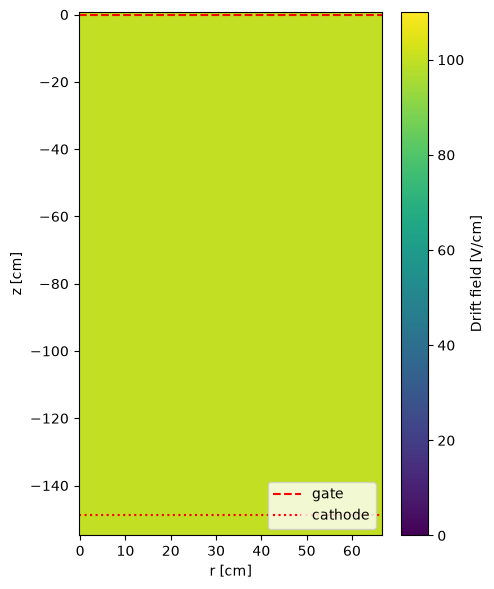

In [5]:
r_plot_points = np.linspace(0.0, tpc_radius, 100)
z_plot_points = np.linspace(z_bottom_pmts, z_liquid_level, 400)
r_plot_grid, z_plot_grid = np.meshgrid(r_plot_points, z_plot_points, indexing="ij")
plot_positions = np.column_stack([r_plot_grid.ravel(), z_plot_grid.ravel()])

field_values = load_map(drift_field_file)(plot_positions).reshape(r_plot_grid.shape)

fig, axis = plt.subplots(figsize=(5, 6))
mesh = axis.pcolormesh(
    r_plot_grid, z_plot_grid, field_values, shading="auto", vmin=0, vmax=1.1 * field_values.max()
)
fig.colorbar(mesh, label="Drift field [V/cm]")
axis.axhline(z_gate, color="red", linestyle="--", label="gate")
axis.axhline(z_cathode, color="red", linestyle=":", label="cathode")
axis.set_xlabel("r [cm]")
axis.set_ylabel("z [cm]")
axis.legend(loc="lower right")
plt.tight_layout()
plt.show()

The fields below the cathode are currently simply the same as above. The fields here are required for the estimation of number of excitons and S1 signal shape. Please keep this in mind when replacing this map with a proper field simulation.

## Step 2: Electron survival map

The survival probability jumps from 0 to 1 at the cathode. With linear interpolation between grid points a jump always becomes a ramp. Therefore this map uses **nearest neighbour** interpolation: every position gets the value of the closest grid point.

The closest grid point changes exactly half way between two grid points. If we place the grid points at $z_\mathrm{cathode} \pm 0.5\,\mathrm{cm}$, $z_\mathrm{cathode} \pm 1.5\,\mathrm{cm}$, ..., the value changes exactly at the cathode. We use a spacing of 1 cm and enough points to cover the volume from the bottom PMTs to the liquid level:

In [6]:
spacing = 1.0  # cm
number_of_points_below_cathode = int(np.ceil(z_cathode - z_bottom_pmts + 0.5))
number_of_points_above_cathode = int(np.ceil(z_liquid_level - z_cathode + 0.5))

z_lowest_point = z_cathode - (number_of_points_below_cathode - 0.5) * spacing
z_highest_point = z_cathode + (number_of_points_above_cathode - 0.5) * spacing
number_of_z_points = number_of_points_below_cathode + number_of_points_above_cathode

z_points = np.linspace(z_lowest_point, z_highest_point, number_of_z_points)
print("Grid points next to the cathode:", z_points[number_of_points_below_cathode - 1 : number_of_points_below_cathode + 1])

Grid points next to the cathode: [-149.1515 -148.1515]


In [7]:
survival_along_z = np.where(z_points < z_cathode, 0.0, 1.0)

survival_map = {
    "name": "electron_survival_below_cathode",
    "description": (
        "Electron survival probability: 0 below the cathode, 1 above. "
        "Use with nearest neighbour interpolation."
    ),
    "coordinate_system": [
        ["r", [0.0, tpc_radius, 2]],
        ["z", [z_lowest_point, z_highest_point, number_of_z_points]],
    ],
    "map": [survival_along_z.tolist(), survival_along_z.tolist()],
}

with open(survival_file, "w") as file:
    json.dump(survival_map, file, indent=1)

The survival map in the $(r, z)$ plane, evaluated with nearest neighbour interpolation. Electrons from below the cathode are lost:

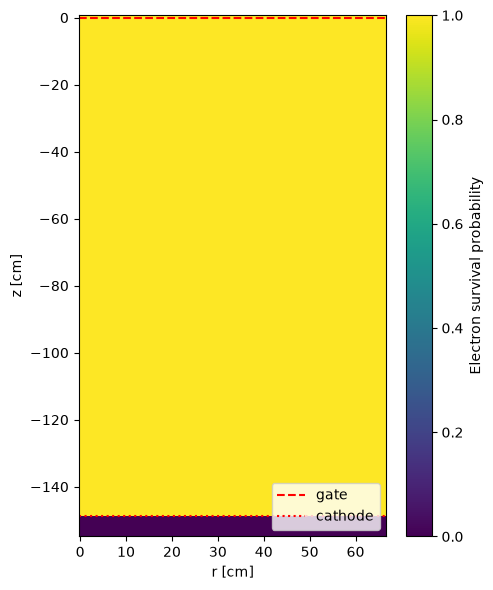

In [8]:
survival_values = load_map(survival_file, method="nearest")(plot_positions).reshape(r_plot_grid.shape)

fig, axis = plt.subplots(figsize=(5, 6))
mesh = axis.pcolormesh(r_plot_grid, z_plot_grid, survival_values, shading="auto", vmin=0, vmax=1)
fig.colorbar(mesh, label="Electron survival probability")
axis.axhline(z_gate, color="red", linestyle="--", label="gate")
axis.axhline(z_cathode, color="red", linestyle=":", label="cathode")
axis.set_xlabel("r [cm]")
axis.set_ylabel("z [cm]")
axis.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Step 3: Drift velocity and diffusion map

Electrons drift from the interaction site up to the gate. Three properties of this drift matter for the S2 signal:

* the **drift velocity** $v$: it sets the drift time, i.e. the time between S1 and S2,
* the **longitudinal diffusion constant** $D_L$: the electron cloud spreads along the drift direction, which makes the S2 wider in time,
* the **transverse diffusion constant** $D_T$: the cloud also spreads in $x$ and $y$.

All three depend on the electric field. We take the drift velocity from NEST and the two diffusion constants from NEST's default parametrizations (see `ember/electron_transport.py` for the formulas and references).

The simulation uses the same simple equations as fuse, with one value per interaction position:

$$t = \frac{|z|}{\bar v}, \qquad \sigma_t^2 = \frac{2 D_L t}{\bar v^2}, \qquad \sigma_{xy}^2 = 2 D_T t$$

If the field changes along the drift path, the electron sees different velocities on its way up. Then the correct drift time is the integral $t = \int dz / v$ from the interaction to the gate, and the same holds for the spreads. The map therefore stores **effective values**: averages along the drift path that turn the simple equations into these integrals. For our constant field they are just the local NEST values. The drift path is a straight vertical line, because we do not simulate field distortion.

The map has three named maps on the same $(r, z)$ grid, in ember's units (cm, ns):

| Map name | Content |
|---|---|
| `drift_speed_map` | average drift velocity from $(r, z)$ up to the gate [cm/ns] |
| `diffusion_longitudinal_map` | effective longitudinal diffusion constant [cm²/ns] |
| `diffusion_transverse_map` | effective transverse diffusion constant [cm²/ns] |

NEST needs the temperature, pressure and density of the liquid xenon:

In [9]:
from ember.electron_transport import (
    build_drift_property_map,
    drift_time_above_gate,
    longitudinal_diffusion_constant_liquid,
)
from ember.maps import save_map_data

liquid_temperature = strax.URLConfig.evaluate_dry("detector://liquid_temperature")
gas_pressure = strax.URLConfig.evaluate_dry("detector://gas_pressure")
xenon_density_liquid = strax.URLConfig.evaluate_dry("detector://xenon_density_liquid")

print("Temperature:", liquid_temperature, "K")
print("Pressure:", gas_pressure, "bar")
print("Density:", xenon_density_liquid, "g/cm3")

Temperature: 177.15 K
Pressure: 1.89 bar
Density: 2.81 g/cm3


The grid covers the same volume as the field map. Along $z$ we use points every ~1 cm, because the averages are integrals along $z$. Along $r$ two points are enough for our constant field. For a realistic field map, use a grid that is at least as fine as the grid of the field map.

In [10]:
field_map = load_map(drift_field_file)

drift_map_r_points = np.linspace(0.0, tpc_radius, 2)
number_of_z_points = int(round(z_liquid_level - z_bottom_pmts)) + 1
drift_map_z_points = np.linspace(z_bottom_pmts, z_liquid_level, number_of_z_points)

drift_map = build_drift_property_map(
    field_map,
    drift_map_r_points,
    drift_map_z_points,
    z_gate=z_gate,
    temperature=liquid_temperature,
    pressure=gas_pressure,
    density=xenon_density_liquid,
)
drift_map["name"] = "field_dependencies_dummy"
drift_map["description"] = (
    "Average drift velocity [cm/ns] and effective longitudinal and transverse diffusion constants "
    f"[cm2/ns] for drifting from (r, z) to the gate, from NEST and the drift field map "
    f"drift_field_constant.json ({drift_field} V/cm). Regenerate when the field map changes."
)

save_map_data(drift_map, drift_map_file)
print("Drift velocity:", drift_map["drift_speed_map"][0, 0] * 1e4, "mm/us")

Drift velocity: 1.3368149323484844 mm/us


The three maps in the $(r, z)$ plane. Our drift field is constant, so all three maps are constant as well. With a realistic field map they would change with $r$ and $z$. The colour scale goes from 0 to slightly above the maximum, so that a constant map does not show tiny rounding differences:

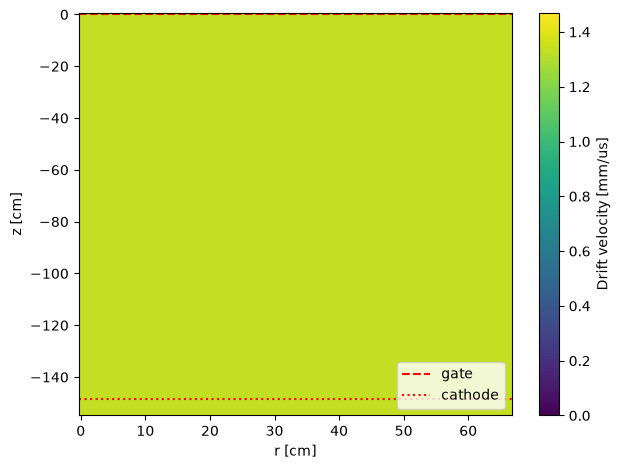

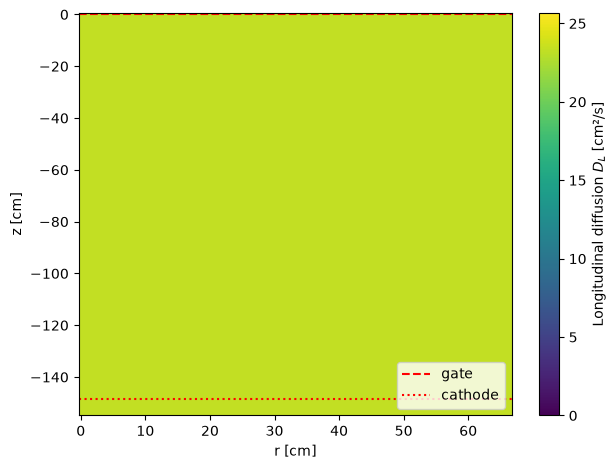

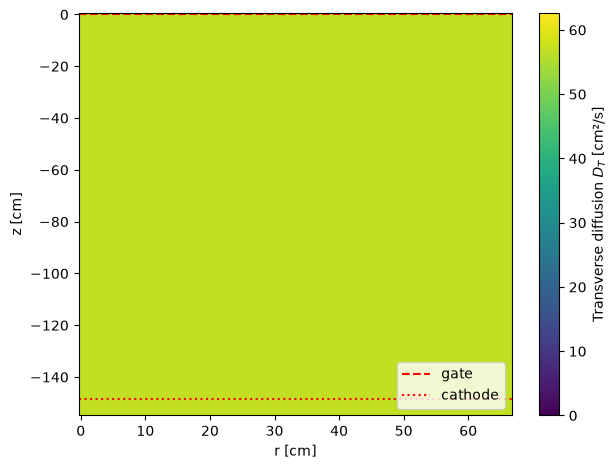

In [11]:
loaded_drift_map_for_plot = load_map(drift_map_file)
drift_map_names = ["drift_speed_map", "diffusion_longitudinal_map", "diffusion_transverse_map"]
drift_map_labels = [
    "Drift velocity [mm/us]",
    "Longitudinal diffusion $D_L$ [cm²/s]",
    "Transverse diffusion $D_T$ [cm²/s]",
]
drift_map_unit_factors = [1e4, 1e9, 1e9]


for map_name, label, unit_factor in zip(
    drift_map_names, drift_map_labels, drift_map_unit_factors
):  
    fig, axis = plt.subplots()
    map_values = loaded_drift_map_for_plot(plot_positions, map_name=map_name) * unit_factor
    mesh = axis.pcolormesh(
        r_plot_grid,
        z_plot_grid,
        map_values.reshape(r_plot_grid.shape),
        shading="auto",
        vmin=0,
        vmax=1.1 * map_values.max(),
    )
    fig.colorbar(mesh, ax=axis, label=label)
    axis.axhline(z_gate, color="red", linestyle="--", label="gate")
    axis.axhline(z_cathode, color="red", linestyle=":", label="cathode")
    axis.legend(loc="lower right")
    axis.set_xlabel("r [cm]")
    axis.set_ylabel("z [cm]")
    plt.tight_layout()
    plt.show()

The drift map gives the drift time and the size of the electron cloud when it reaches the gate. Deeper interactions drift longer, so their electron clouds are wider:

In [12]:
z_values = np.linspace(z_gate, z_cathode, 1000)
positions = np.zeros((len(z_values),2))
positions[:, 1] = z_values

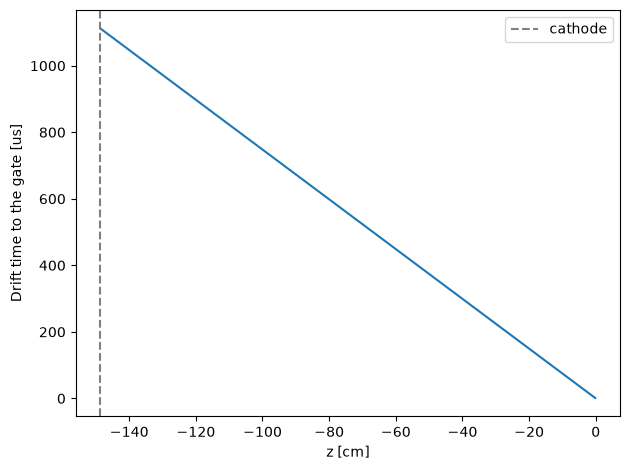

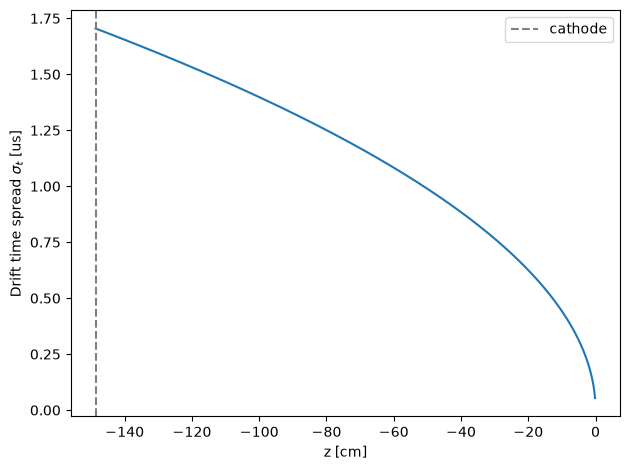

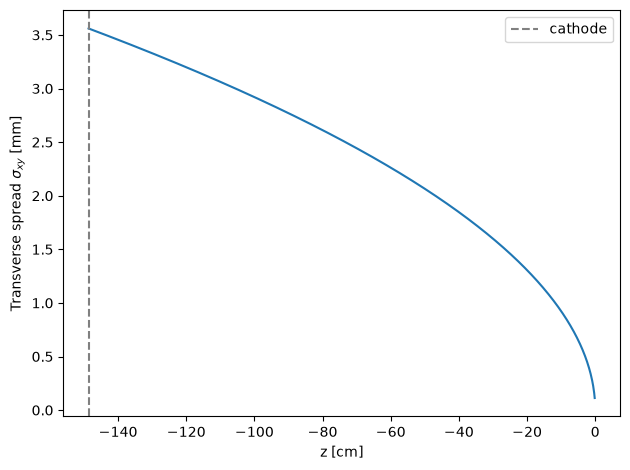

Drift time from the cathode to the gate: 1112 us


In [13]:
loaded_drift_map = load_map(drift_map_file)

drift_speed = loaded_drift_map(positions, map_name="drift_speed_map")
diffusion_longitudinal = loaded_drift_map(positions, map_name="diffusion_longitudinal_map")
diffusion_transverse = loaded_drift_map(positions, map_name="diffusion_transverse_map")

is_below_gate = z_values < z_gate
drift_time = (z_gate - z_values[is_below_gate]) / drift_speed[is_below_gate]
time_spread = np.sqrt(2 * diffusion_longitudinal[is_below_gate] * drift_time) / drift_speed[is_below_gate]
transverse_spread = np.sqrt(2 * diffusion_transverse[is_below_gate] * drift_time)

fig, axis = plt.subplots()
axis.plot(z_values[is_below_gate], drift_time / 1e3)
axis.set_ylabel("Drift time to the gate [us]")
axis.axvline(z_cathode, color="gray", linestyle="--", label="cathode")
axis.set_xlabel("z [cm]")
axis.legend()
plt.tight_layout()
plt.show()

fig, axis = plt.subplots()
axis.plot(z_values[is_below_gate], time_spread / 1e3)
axis.set_ylabel("Drift time spread $\\sigma_t$ [us]")
axis.axvline(z_cathode, color="gray", linestyle="--", label="cathode")
axis.set_xlabel("z [cm]")
axis.legend()
plt.tight_layout()
plt.show()

fig, axis = plt.subplots()
axis.plot(z_values[is_below_gate], transverse_spread * 10)
axis.set_ylabel("Transverse spread $\\sigma_{xy}$ [mm]")
axis.axvline(z_cathode, color="gray", linestyle="--", label="cathode")
axis.set_xlabel("z [cm]")
axis.legend()
plt.tight_layout()
plt.show()    

drift_speed_at_cathode = loaded_drift_map([[30.0, z_cathode]], map_name="drift_speed_map")[0]
print(f"Drift time from the cathode to the gate: {(z_gate - z_cathode) / drift_speed_at_cathode / 1e3:.0f} us")

## Step 4: Drift between gate and liquid surface

Between the gate and the liquid surface the field is much stronger (the **extraction field**), so the electrons drift faster there. This region is thin and the field is nearly constant, so the simulation uses two numbers from `detector.yaml` instead of a map: the drift time from the gate to the surface and the longitudinal diffusion constant there. Here we compute both from NEST. If you change the extraction field or the liquid level, copy the printed values into `detector.yaml` (a unit test checks that they agree):

In [14]:
extraction_field_liquid = strax.URLConfig.evaluate_dry("detector://extraction_field_liquid")

drift_time_gate = drift_time_above_gate(
    z_liquid_level,
    z_gate,
    extraction_field_liquid,
    temperature=liquid_temperature,
    pressure=gas_pressure,
    density=xenon_density_liquid,
)
diffusion_constant_longitudinal_gate = longitudinal_diffusion_constant_liquid(extraction_field_liquid)

print("Extraction field in the liquid:", extraction_field_liquid, "V/cm")
print(f"drift_time_gate: {drift_time_gate:.1f}  (detector.yaml: {strax.URLConfig.evaluate_dry('detector://drift_time_gate')})")
print(f"diffusion_constant_longitudinal_gate: {diffusion_constant_longitudinal_gate:.4g}  (detector.yaml: {strax.URLConfig.evaluate_dry('detector://diffusion_constant_longitudinal_gate')})")

Extraction field in the liquid: 3571.4 V/cm
drift_time_gate: 1921.9  (detector.yaml: 1984.2)
diffusion_constant_longitudinal_gate: 8.685e-09  (detector.yaml: 9.147e-09)
